# Founder burden and fitness in GrENE-Net — SNPs, insertions and deletions in one model

**Question.** Do founders that carry more variants in coding sequence do worse in the experiment — and
is that true for structural variants, not only for SNPs? One mixed model answers it for SNPs, insertions
and deletions **together**, so each class's effect is estimated with the other two held fixed, and with
relatedness between founders in the model.

**Contents.** *Figure 1* — the effect of each class, per carried variant. *Figure 2* — the same effect
garden by garden, and against garden temperature. *Supplementary Figure S1* — how the model was
simplified. *Supplementary Figure S2* — the full model on the scale it is fitted (per SD). *Table S1* —
joint models from one class up to all three. *Key numbers.* *Supplementary Figures S3–S4* — the same
model for promoter burden; *S5* — its intergenic terms garden by garden. *One-stage model* — all 7,161
founder × garden observations in one mixed model (Figures O1–O3). The final models are in
`sv_burden_final_models.ipynb`.

**Unit and filters.** SV **event** (arch3 alleles of a pangenome bubble merged with `truvari collapse`
defaults). Every variant called in ≥ 90% of the 231 founders and carried by ≥ 2 of them; **shared**
variants only (carried by both cold- and warm-origin founders); all SNP records. Context,
first match wins: CDS > UTR > intron > reference TE > promoter (≤ 2 kb upstream) > intergenic.

In [1]:

import os
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
KINDS=("snp","ins","del"); KC={"snp":"0.15","ins":"#D95F02","del":"#1B9E77"}; YL={"snp":"SNPs","ins":"insertions","del":"deletions"}
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="−"                                                            # typographic minus for labels
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
def pfmt(p,n=None):
    if n is not None and p==0: return f"p < {1/n:.0e}".replace("e-0","e-")
    return "p < 0.001" if p<0.001 else f"p = {p:.2g}"
def save(fig,name): fig.savefig(f"{G}/plots/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{G}/plots/{name}.pdf",bbox_inches="tight")
FM=pd.read_csv(f"{G}/sv_burden_full_model_event.csv").set_index("term")          # mean fitness, all terms (_sv_burden_full_model.py)
FG=pd.read_csv(f"{G}/sv_burden_full_model_by_garden_event.csv")                   # the same model per garden
SIMP=pd.read_csv(f"{G}/sv_burden_model_simplify_event.csv")                        # model ladder (_sv_burden_model_simplify.py)
JOINT=pd.read_csv(f"{G}/sv_burden_joint_snp_ins_del_event.csv")                    # one class up to all three
PERM=np.load(f"{G}/sv_burden_full_model_perm_event.npz")                          # null draws per coding term (per garden, per SD)
def ew_slope(t):
    # equal-weights (OLS) slope of the per-garden coefficients on garden bio1, per SD; permutation p from the saved null
    # per-garden coefficients (same founder-label shuffle in every garden, so the dependence between gardens is kept)
    g0=FG[FG.term==t]; x=g0.bio1.to_numpy(); xc=x-x.mean(); b=g0.beta_sd.to_numpy()
    obs=(xc@(b-b.mean()))/(xc@xc); NGt=PERM[f"{t}_null_garden"].astype(float); nl=((NGt-NGt.mean(1,keepdims=True))@xc)/(xc@xc)
    return obs,(np.abs(nl)>=abs(obs)).mean()
NF=len(pd.read_csv(f"{G}/founder_burden_event.csv",usecols=["founder"])); NG=FG.site.nunique(); NPERM=int(FM.n_perm.dropna().iloc[0])
print(f"{NF} founders, {NG} gardens, {NPERM:,} founder-label permutations per tested coding term; kinship share of variance {FM.h2.iloc[0]:.2f}")


231 founders, 31 gardens, 3,000 founder-label permutations per tested coding term; kinship share of variance 0.88


## Figure 1 — the effect of each variant class, per carried variant

**Model.** For founder *f* and garden *s*, *y*<sub>f</sub> = log[(*H*<sub>0,f</sub> + Δ*H*<sub>s,f</sub> + 10⁻⁵) / (*H*<sub>0,f</sub> + 10⁻⁵)]
is the founder's log change in frequency from the seed mix to the last generation, averaged over the
31 gardens:

> *y* = β₀ + Σ<sub>k ∈ {SNP, ins, del}</sub> [ β<sub>k,coding</sub>·*r*<sub>k,coding</sub> + β<sub>k,intergenic</sub>·*r*<sub>k,intergenic</sub> ]
> + γ·[assembly route] + *u* + ε,   *u* ~ N(0, σ²<sub>g</sub>**K**)

*r* = the variants of that class and context the founder carries ÷ those it is called at; **K** = SNP
kinship. Each class enters twice, coding and intergenic, so its coding coefficient asks: at the same
overall load of that class, does carrying more of it **in coding sequence** change fitness? Assembly
route (cactus vs short-read) is the single technical term; the SV and SNP call rates were redundant with
it and with each other, and dropping them leaves the coding-insertion coefficient unchanged
(Supplementary Figure S1).

**Per carried variant.** The model is fitted on standardised rates; each coefficient is then divided by
the number of variants one SD of that rate represents, giving the % change in founder fitness for **one
more carried variant**, all else fixed. Only this scale compares classes: one SD of coding burden is
≈ 10,000 SNPs but ≈ 10 insertions. It is the *average* over the class's variants — most coding SNPs are
synonymous or harmless — and a local slope, not something to multiply up to a total load. The per-SD
version is Supplementary Figure S2.

**(a)** Each class on its own x-range, so every estimate and interval is readable. **(b)** The same six
values on one shared axis, so the classes compare directly. Circles = coding, squares = intergenic;
filled = p < 0.05, where coding terms use the founder-label permutation p (3,000 draws: the term's rate is
residualised on all other terms and the residual shuffled across founders) and intergenic terms the Wald p.

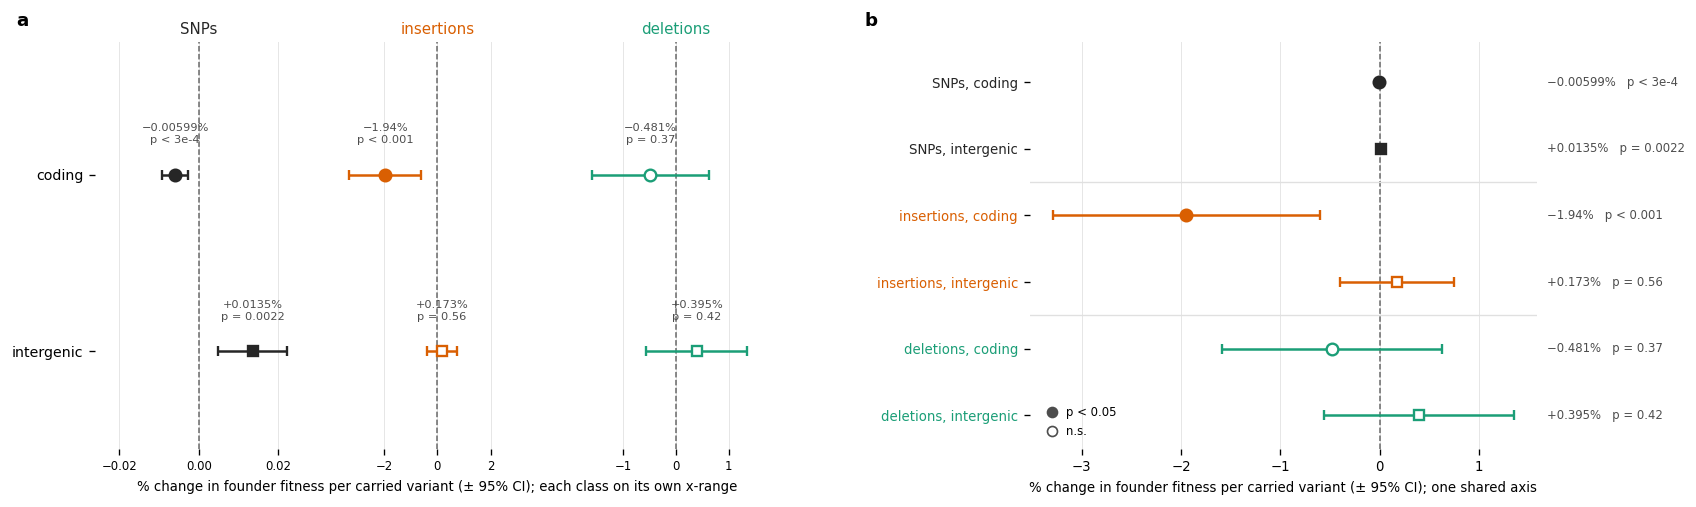

Figure 1 — full model on mean fitness (all terms fitted together):
                  term % per variant                95% CI per SD variants per SD  Wald p permutation p
          SNPs, coding     −0.00599% [−0.00927%, −0.0027%] −0.602        10,051.6 0.00036      p < 3e-4
      SNPs, intergenic      +0.0135% [+0.00488%, +0.0222%] +0.590         4,353.4  0.0022              
    insertions, coding        −1.94%     [−3.29%, −0.598%] −0.185             9.5  0.0046     p < 0.001
insertions, intergenic       +0.173%    [−0.402%, +0.748%] +0.067            38.6    0.56              
     deletions, coding       −0.481%     [−1.59%, +0.626%] −0.041             8.5    0.39      p = 0.37
 deletions, intergenic       +0.395%      [−0.56%, +1.35%] +0.057            14.6    0.42              
assembly route (cactus − short-read): +0.096 ± 0.118 (Wald p = 0.42)


In [2]:

fig=plt.figure(figsize=(15.5,4.4)); gsf=fig.add_gridspec(1,2,width_ratios=[1.35,1],wspace=0.42)
def pval(t): return FM.loc[t,"p_perm"] if t.endswith("CDS") else FM.loc[t,"p_wald"]
def plab(t): return pfmt(pval(t),NPERM) if t.endswith("CDS") else pfmt(pval(t))
# (a) one small panel per class, own symmetric x-range
gsa=gsf[0,0].subgridspec(1,3,wspace=0.15)
for ci,k in enumerate(KINDS):
    a=fig.add_subplot(gsa[0,ci]); style(a); a.axvline(0,color="0.4",lw=0.9,ls="--")
    ext=max(abs(100*FM.loc[f"{k}_{x}","beta_per_variant"])+2.3*100*FM.loc[f"{k}_{x}","se_per_variant"] for x in ("CDS","intergenic"))
    for yi,(x,mk) in enumerate((("CDS","o"),("intergenic","s"))):
        t=f"{k}_{x}"; b=100*FM.loc[t,"beta_per_variant"]; s_=100*FM.loc[t,"se_per_variant"]; sig=pval(t)<0.05
        a.errorbar(b,yi,xerr=1.96*s_,fmt=mk,ms=7 if x=="CDS" else 6,color=KC[k],mfc=KC[k] if sig else "white",mew=1.4,capsize=3,elinewidth=1.5)
        a.annotate(f"{pct(b)}\n{plab(t)}",xy=(b,yi-0.17),ha="center",va="bottom",fontsize=6.8,color="0.3")
    a.set_xlim(-ext*1.1,ext*1.1); a.set_ylim(1.55,-0.75); a.set_yticks([0,1])
    a.set_yticklabels(["coding","intergenic"] if ci==0 else ["",""],fontsize=8.5)
    if ci>0: a.tick_params(axis="y",left=False)
    a.tick_params(axis="x",labelsize=7); a.annotate(YL[k],xy=(0.5,1.02),xycoords="axes fraction",ha="center",fontsize=9,color=KC[k])
    if ci==0: panel(a,"a",x=-0.32)
    if ci==1: a.set_xlabel("% change in founder fitness per carried variant (± 95% CI); each class on its own x-range",fontsize=8)
# (b) all six on one shared axis
a=fig.add_subplot(gsf[0,1]); style(a); panel(a,"b",x=-0.3); a.axvline(0,color="0.4",lw=0.9,ls="--")
rows_=[(f"{k}_{x}",k,x) for k in KINDS for x in ("CDS","intergenic")]
for yi,(t,k,x) in enumerate(rows_):
    b=100*FM.loc[t,"beta_per_variant"]; s_=100*FM.loc[t,"se_per_variant"]; sig=pval(t)<0.05
    a.errorbar(b,yi,xerr=1.96*s_,fmt="o" if x=="CDS" else "s",ms=7 if x=="CDS" else 6,color=KC[k],mfc=KC[k] if sig else "white",mew=1.4,capsize=3,elinewidth=1.5)
    a.annotate(f"{pct(b)}   {plab(t)}",xy=(1.02,yi),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.3",annotation_clip=False)
    if yi in (1,3): a.axhline(yi+0.5,color="0.88",lw=0.8)
a.set_yticks(range(len(rows_))); a.set_yticklabels([f"{YL[k]}, {'coding' if x=='CDS' else 'intergenic'}" for _,k,x in rows_],fontsize=8)
for tl,(_,k,_) in zip(a.get_yticklabels(),rows_): tl.set_color(KC[k])
a.set_ylim(len(rows_)-0.5,-0.6); a.set_xlabel("% change in founder fitness per carried variant (± 95% CI); one shared axis",fontsize=8)
a.errorbar([],[],fmt="o",color="0.3",ms=6,label="p < 0.05"); a.errorbar([],[],fmt="o",color="0.3",mfc="white",ms=6,label="n.s.")
a.legend(fontsize=7,loc="lower left",handletextpad=0.2)
save(fig,"burden_full_model_effects"); plt.show()
T=pd.DataFrame({"term":[f"{YL[t.split('_')[0]]}, {'coding' if t.endswith('CDS') else 'intergenic'}" for t in FM.index[:6]],
                "% per variant":[pct(100*FM.loc[t,'beta_per_variant']) for t in FM.index[:6]],
                "95% CI":[f"[{pct(100*(FM.loc[t,'beta_per_variant']-1.96*FM.loc[t,'se_per_variant']))}, {pct(100*(FM.loc[t,'beta_per_variant']+1.96*FM.loc[t,'se_per_variant']))}]" for t in FM.index[:6]],
                "per SD":[f"{FM.loc[t,'beta_sd']:+.3f}".replace("-",M) for t in FM.index[:6]],
                "variants per SD":[f"{FM.loc[t,'variants_per_sd']:,.1f}" for t in FM.index[:6]],
                "Wald p":[f"{FM.loc[t,'p_wald']:.2g}" for t in FM.index[:6]],
                "permutation p":[pfmt(FM.loc[t,'p_perm'],NPERM) if t.endswith('CDS') else "" for t in FM.index[:6]]})
print("Figure 1 — full model on mean fitness (all terms fitted together):"); print(T.to_string(index=False))
print(f"assembly route (cactus − short-read): {FM.loc['cactus','beta_sd']:+.3f} ± {FM.loc['cactus','se_sd']:.3f} (Wald p = {FM.loc['cactus','p_wald']:.2g})")


## Figure 2 — garden by garden

The same full model fitted in each of the 31 gardens; one row per coding term (SNPs, insertions,
deletions). All panels share **one per-variant scale**, so the classes compare directly — the SNP
estimates are real but tiny on it (values in the labels and the table below).

**Left:** each garden's coefficient ± 95% CI, gardens sorted by effect (most negative at the bottom) and
coloured by garden temperature. Line and band = pooled coefficient ± 1.96 SE, with the SE from the
**founder-label permutation**: the 31 fits share the same founders, so the textbook inverse-variance SE
(printed for comparison) is 2–2.5× too small. **Right:** the same coefficients against garden
temperature (grey bars = 95% CI), with an ordinary least-squares line, every garden weighted equally; its
p-value is from the same founder-label permutation (the saved null coefficients of all 31 gardens), which
keeps the dependence between gardens. A leave-one-garden-out check of the slope is printed.

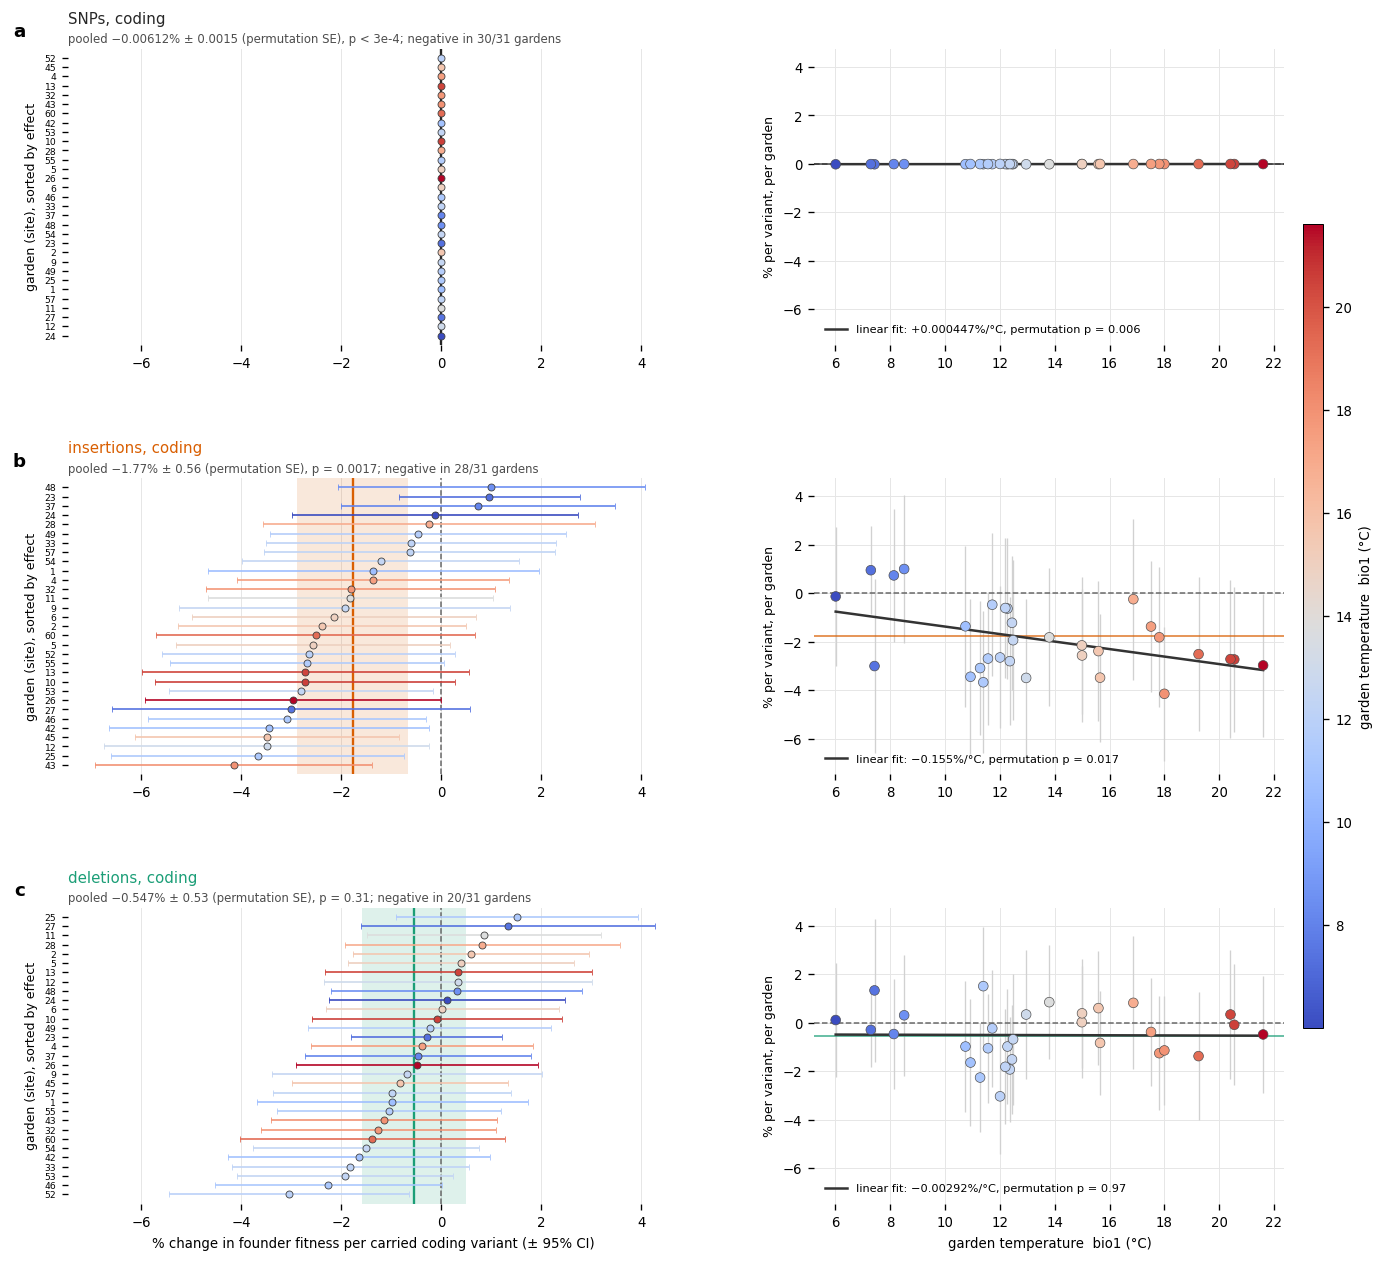

Figure 2 — per-garden summary, coding terms:
coding term                             SNPs       insertions    deletions
pooled % per variant               −0.00612%           −1.77%      −0.547%
SE (permutation)                      0.0015             0.56         0.53
SE (textbook)                        0.00064             0.26         0.22
pooled p (perm.)                    p < 3e-4       p = 0.0017     p = 0.31
gardens < 0                            30/31            28/31        20/31
slope %/°C (equal weights)        +0.000447%          −0.155%    −0.00292%
slope p (perm.)                    p = 0.006        p = 0.017     p = 0.97
worst leave-one-out p (OLS)  0.012 (site 24)  0.036 (site 23)  1 (site 23)


In [3]:

B1=FG.drop_duplicates("site").bio1; NORM=mpl.colors.Normalize(B1.min(),B1.max()); CMAP=plt.get_cmap("coolwarm")
def mreg(b,v,x):
    w=1/v; X=np.column_stack([np.ones(b.size),x]); XtW=X.T*w; bh=np.linalg.solve(XtW@X,XtW@b); return bh,np.sqrt(np.diag(np.linalg.inv(XtW@X)))
fig=plt.figure(figsize=(13.5,12.5)); gsg=fig.add_gridspec(3,2,width_ratios=[1.3,1],wspace=0.25,hspace=0.45); OUTG=[]; AXL=[]; AXR=[]
for r_,k in enumerate(KINDS):
    t=f"{k}_CDS"; g=FG[FG.term==t].sort_values("beta_sd").reset_index(drop=True); r=FM.loc[t]; sc=r.beta_per_variant/r.beta_sd
    b=100*g.beta_per_variant.to_numpy(); se=100*g.se_per_variant.to_numpy(); x=g.bio1.to_numpy(); v=se**2
    po=100*r.pooled_sd*sc; pse=100*r.pooled_se_perm*sc; pse_ind=100*r.pooled_se_independent*sc
    a=fig.add_subplot(gsg[r_,0]); AXL.append(a); style(a); panel(a,"abc"[r_],x=-0.07); a.axvline(0,color="0.4",lw=0.9,ls="--")
    a.axvspan(po-1.96*pse,po+1.96*pse,color=KC[k],alpha=0.14,lw=0); a.axvline(po,color=KC[k],lw=1.4)
    for yi in range(len(g)):
        c_=CMAP(NORM(g.bio1[yi])); a.errorbar(b[yi],yi,xerr=1.96*se[yi],fmt="o",ms=4.2,color=c_,mec="0.25",mew=0.5,ecolor=c_,elinewidth=1.0,capsize=1.6)
    a.set_yticks(range(len(g))); a.set_yticklabels(g.site.astype(int),fontsize=5.5); a.set_ylim(-1,len(g)); a.set_ylabel("garden (site), sorted by effect",fontsize=7.5)
    a.annotate(f"{YL[k]}, coding", xy=(0.0,1.075),xycoords="axes fraction",fontsize=9,color=KC[k],va="bottom",annotation_clip=False)
    a.annotate(f"pooled {pct(po)} ± {pse:.2g} (permutation SE), {pfmt(r.p_perm_pooled,NPERM)}; negative in {int(r.negative_in)}/{NG} gardens",
               xy=(0.0,1.01),xycoords="axes fraction",ha="left",va="bottom",fontsize=7,color="0.3",annotation_clip=False)
    if r_==2: a.set_xlabel("% change in founder fitness per carried coding variant (± 95% CI)",fontsize=8)
    a=fig.add_subplot(gsg[r_,1]); AXR.append(a); style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--"); a.axhline(po,color=KC[k],lw=1.1,alpha=0.7)
    a.errorbar(x,b,yerr=1.96*se,fmt="none",ecolor="0.82",elinewidth=0.8,zorder=1)
    a.scatter(x,b,s=34,c=x,cmap=CMAP,norm=NORM,linewidth=0.4,edgecolor="0.3",zorder=3)
    su,_=mreg(b,np.ones_like(v),x); ews,ewp=ew_slope(t); xx=np.linspace(x.min(),x.max(),50)
    a.plot(xx,su[0]+su[1]*xx,color="0.2",lw=1.5,label=f"linear fit: {pct(su[1])}/°C, permutation {pfmt(ewp,NPERM)}")
    a.set_ylabel("% per variant, per garden",fontsize=7.5); a.legend(fontsize=6.8,loc="lower left")
    if r_==2: a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
    LOO=[]
    for i in range(len(b)):
        m_=np.ones(len(b),bool); m_[i]=False; lr=stats.linregress(x[m_],b[m_]); LOO.append((int(g.site[i]),lr.slope,lr.pvalue))
    L_=pd.DataFrame(LOO,columns=["site","slope","p"]).sort_values("p",ascending=False).iloc[0]
    OUTG.append({"coding term":YL[k],"pooled % per variant":pct(po),"SE (permutation)":f"{pse:.2g}","SE (textbook)":f"{pse_ind:.2g}",
                 "pooled p (perm.)":pfmt(r.p_perm_pooled,NPERM),"gardens < 0":f"{int(r.negative_in)}/{NG}",
                 "slope %/°C (equal weights)":pct(su[1]),"slope p (perm.)":pfmt(ewp,NPERM),"worst leave-one-out p (OLS)":f"{L_.p:.2g} (site {int(L_.site)})"})
xl=[a.get_xlim() for a in AXL]; yl=[a.get_ylim() for a in AXR]                        # one shared per-variant scale
for a in AXL: a.set_xlim(min(v_[0] for v_ in xl),max(v_[1] for v_ in xl))
for a in AXR: a.set_ylim(min(v_[0] for v_ in yl),max(v_[1] for v_ in yl))
for a in AXL[:2]+AXR[:2]: a.tick_params(labelbottom=True)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM,cmap=CMAP),ax=AXL+AXR,pad=0.015,fraction=0.016,aspect=40); cb.set_label("garden temperature  bio1 (°C)",fontsize=8)
save(fig,"burden_full_model_by_garden"); plt.show()
print("Figure 2 — per-garden summary, coding terms:"); print(pd.DataFrame(OUTG).T.to_string(header=False))


## Supplement

**Supplementary Figure S1 — how the model was simplified.** Insertions alone (before the joint model).
**(a)** Every coefficient, model by model, from the original five covariates down to the coding rate
alone; kinship in all; AIC from maximum-likelihood refits. The coding-insertion coefficient stays at
−0.21 to −0.23 per SD in every model that keeps the intergenic rate, and collapses without it — the
contrast with the founder's overall insertion load is what carries the effect. The two call rates and
the assembly route are interchangeable: whichever is left in picks up the same technical difference, so
one is enough. **(b)** The coding-insertion coefficient with and without the kinship term: without it
the coefficient inflates and the fit is much worse (AIC ≈ 410 vs ≈ 355).

**Supplementary Figure S2 — the full model per SD.** The scale the model is fitted on, including the
assembly route. Here SNPs look largest because one SD of coding-SNP burden is ≈ 10,000 SNPs against
≈ 10 coding insertions; Figure 1 divides that out.

**Table S1 — joint models.** From one class alone up to all three: the coding-insertion coefficient
is stable, deletions are null throughout, and the insertion coding-minus-intergenic contrast weakens
once SNPs are in, because the intergenic insertion and SNP rates are highly correlated (r = 0.93).

*Caveats.* The model form (coding and intergenic rates, one technical term) was settled after looking
at these fits, which is why the whole ladder is shown. The coding-insertion effect depends on the
call-rate floor: at a 70% floor it weakens to −0.11 per SD (p = 0.11; `sv_main_figures_cr70.ipynb`), and
the coding-insertion rate correlates with founder SV call rate (r = 0.45).

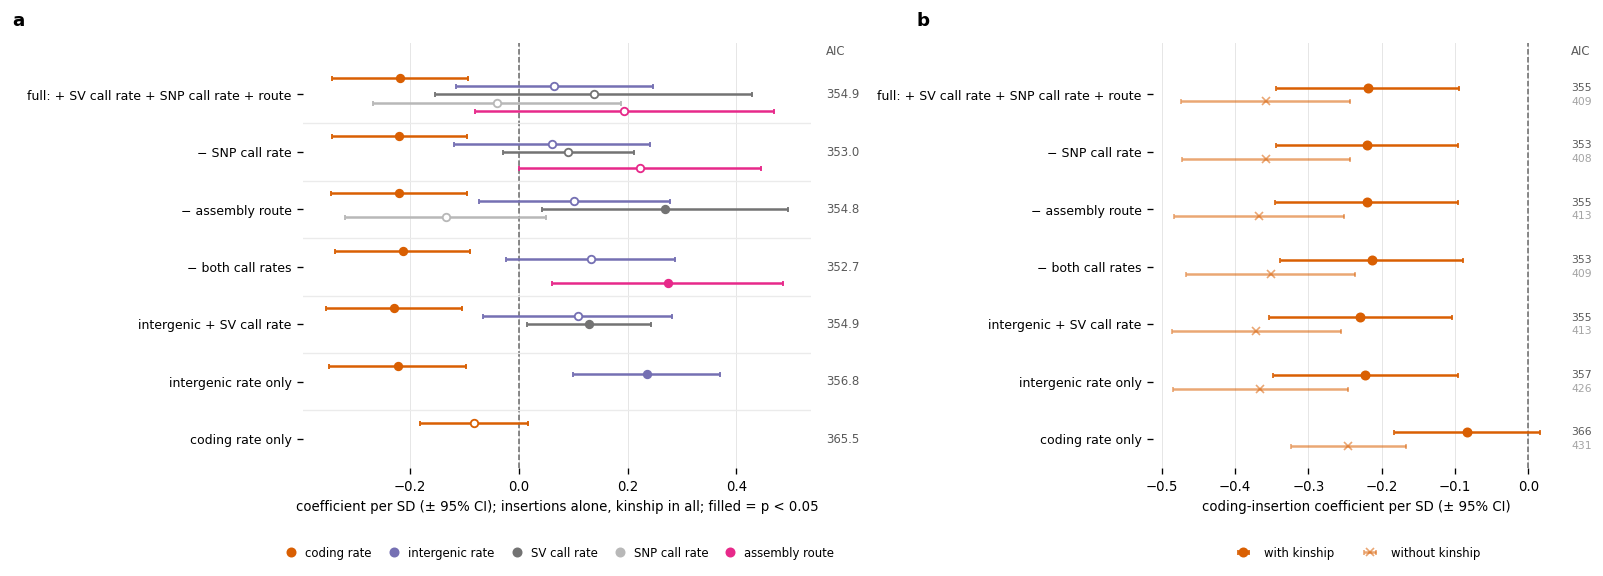

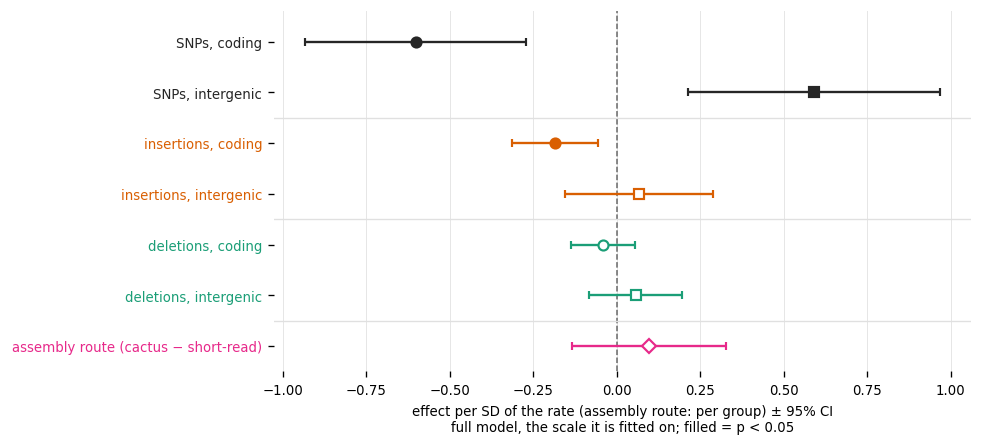

Table S1 — joint models, coefficient per SD (p), kinship and assembly route in all:
model                                        SNPs               ins              del        SNPs + ins        ins + del         all three
term                                                                                                                                     
SNPs, coding                       −0.678 (2e-05)                                     −0.608 (0.00014)                   −0.602 (0.00036)
SNPs, intergenic                 +0.586 (0.00023)                                      +0.605 (0.0014)                    +0.590 (0.0022)
insertions, coding                                 −0.214 (0.00077)                    −0.184 (0.0048)  −0.206 (0.0016)   −0.185 (0.0046)
insertions, intergenic                               +0.132 (0.096)                      +0.063 (0.58)   +0.156 (0.069)     +0.067 (0.56)
deletions, coding                                                     −0.076 (0.093)    

In [4]:

MODL={"full":"full: + SV call rate + SNP call rate + route","- callrate_snp":"− SNP call rate","- cactus":"− assembly route",
      "- both call rates":"− both call rates","intergenic + callrate_sv":"intergenic + SV call rate","intergenic only":"intergenic rate only",
      "CDS only":"coding rate only"}
TERML={"CDS":("coding rate",KC["ins"]),"intergenic":("intergenic rate","#7570B3"),"callrate_sv":("SV call rate","0.45"),
       "callrate_snp":("SNP call rate","0.72"),"cactus":("assembly route","#E7298A")}
MOD=list(MODL); I=SIMP[(SIMP.kind=="ins")&SIMP.fit.str.startswith("LMM")]
fig,ax=plt.subplots(1,2,figsize=(13.5,4.6),gridspec_kw=dict(width_ratios=[1.25,1],wspace=0.75))
a=ax[0]; style(a); panel(a,"a",x=-0.55); a.axvline(0,color="0.4",lw=0.9,ls="--")
for i,m in enumerate(MOD):
    d=I[I.model==m].set_index("term")
    for j,t in enumerate(TERML):
        if t in d.index:
            r=d.loc[t]; a.errorbar(r.beta,i+(j-2)*0.14,xerr=1.96*r.se,fmt="o",ms=4.5,color=TERML[t][1],mfc=TERML[t][1] if r.p<0.05 else "white",mew=1.1,capsize=1.5)
    a.annotate(f"{d.aic.iloc[0]:.1f}",xy=(1.03,i),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.35",annotation_clip=False)
    if i<len(MOD)-1: a.axhline(i+0.5,color="0.92",lw=0.8)
a.annotate("AIC",xy=(1.03,-0.75),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.35",annotation_clip=False)
a.set_yticks(range(len(MOD))); a.set_yticklabels([MODL[m] for m in MOD],fontsize=7.5); a.set_ylim(len(MOD)-0.5,-0.9)
from matplotlib.lines import Line2D
a.legend(handles=[Line2D([],[],marker="o",ls="",color=c_,ms=5,label=l_) for l_,c_ in TERML.values()],fontsize=7,loc="upper center",bbox_to_anchor=(0.5,-0.16),ncol=5,handletextpad=0.2,columnspacing=0.9)
a.set_xlabel("coefficient per SD (± 95% CI); insertions alone, kinship in all; filled = p < 0.05",fontsize=8)
a=ax[1]; style(a); panel(a,"b",x=-0.55); a.axvline(0,color="0.4",lw=0.9,ls="--")
for fit,mk,al,dy in (("LMM (kinship)","o",1,-0.12),("OLS (no kinship)","x",0.55,0.12)):
    d=SIMP[(SIMP.kind=="ins")&(SIMP.term=="CDS")&(SIMP.fit==fit)].set_index("model").reindex(MOD)
    a.errorbar(d.beta,np.arange(len(MOD))+dy,xerr=1.96*d.se,fmt=mk,ms=5,color=KC["ins"],alpha=al,capsize=1.5,
               label=f"{'with' if mk=='o' else 'without'} kinship")
    for i,m in enumerate(MOD): a.annotate(f"{d.aic[m]:.0f}",xy=(1.03,i+dy),xycoords=("axes fraction","data"),va="center",fontsize=6.5,color="0.35",alpha=al,annotation_clip=False)
a.annotate("AIC",xy=(1.03,-0.75),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.35",annotation_clip=False)
a.set_yticks(range(len(MOD))); a.set_yticklabels([MODL[m] for m in MOD],fontsize=7.5); a.set_ylim(len(MOD)-0.5,-0.9)
a.legend(fontsize=7,loc="upper center",bbox_to_anchor=(0.5,-0.16),ncol=2)
a.set_xlabel("coding-insertion coefficient per SD (± 95% CI)",fontsize=8)
save(fig,"burden_model_ladder"); plt.show()

# Supplementary Figure S2 -- the full model per SD, with the assembly route
fig,a=plt.subplots(figsize=(7.5,3.9)); style(a); a.axvline(0,color="0.4",lw=0.9,ls="--")
rows_=[(f"{k}_{x}",f"{YL[k]}, {'coding' if x=='CDS' else 'intergenic'}",KC[k],"o" if x=="CDS" else "s") for k in KINDS for x in ("CDS","intergenic")]+[("cactus","assembly route (cactus − short-read)","#E7298A","D")]
for yi,(t,lab,col,mk) in enumerate(rows_):
    r=FM.loc[t]; p=r.p_perm if t.endswith("CDS") else r.p_wald
    a.errorbar(r.beta_sd,yi,xerr=1.96*r.se_sd,fmt=mk,ms=6,color=col,mfc=col if p<0.05 else "white",mew=1.3,capsize=2.5,elinewidth=1.4)
    if yi in (1,3,5): a.axhline(yi+0.5,color="0.88",lw=0.8)
a.set_yticks(range(len(rows_))); a.set_yticklabels([l for _,l,_,_ in rows_],fontsize=8); a.set_ylim(len(rows_)-0.5,-0.6)
for tl,(_,_,col,_) in zip(a.get_yticklabels(),rows_): tl.set_color(col)
a.set_xlabel("effect per SD of the rate (assembly route: per group) ± 95% CI\nfull model, the scale it is fitted on; filled = p < 0.05",fontsize=8)
save(fig,"burden_full_model_per_sd"); plt.show()

# Table S1 -- joint models
JM={"SNP alone":"SNPs","insertions alone":"ins","deletions alone":"del","SNP + insertions":"SNPs + ins","insertions + deletions":"ins + del","SNP + insertions + deletions":"all three"}
TL={"snp_CDS":"SNPs, coding","snp_intergenic":"SNPs, intergenic","ins_CDS":"insertions, coding","ins_intergenic":"insertions, intergenic",
    "del_CDS":"deletions, coding","del_intergenic":"deletions, intergenic","cactus":"assembly route",
    "snp: CDS - intergenic":"SNPs: coding − intergenic","ins: CDS - intergenic":"insertions: coding − intergenic","del: CDS - intergenic":"deletions: coding − intergenic"}
J=JOINT.copy(); J["cell"]=J.beta.map(lambda v:f"{v:+.3f}".replace("-",M))+" ("+J.p.map(lambda p:f"{p:.2g}")+")"
TS=J.pivot(index="term",columns="model",values="cell").reindex(list(TL))[list(JM)].fillna("").rename(index=TL,columns=JM)
TS.loc["AIC"]=[f"{J[J.model==m].aic.iloc[0]:.1f}" for m in JM]
print("Table S1 — joint models, coefficient per SD (p), kinship and assembly route in all:"); print(TS.to_string())


## Key numbers

Printed from the saved results, so they always match the figures above.

In [5]:

def line(t):
    r=FM.loc[t]; s=r.beta_per_variant/r.beta_sd
    return (f"{pct(100*r.beta_per_variant)} per carried variant [{pct(100*(r.beta_per_variant-1.96*r.se_per_variant))}, {pct(100*(r.beta_per_variant+1.96*r.se_per_variant))}], "
            f"permutation {pfmt(r.p_perm,NPERM)};  per garden: pooled {pct(100*r.pooled_sd*s)}, {pfmt(r.p_perm_pooled,NPERM)}, negative in {int(r.negative_in)}/{NG}, "
            f"slope on garden temperature {pct(100*ew_slope(t)[0]*s)}/°C (equal weights), {pfmt(ew_slope(t)[1],NPERM)}")
for k in KINDS: print(f"coding {YL[k]:<11} {line(f'{k}_CDS')}")
print(f"\nper carried coding variant, insertion / SNP = {FM.loc['ins_CDS','beta_per_variant']/FM.loc['snp_CDS','beta_per_variant']:.0f}x (point estimates; the SNP average includes the many harmless coding SNPs)")
print(f"kinship share of variance {FM.h2.iloc[0]:.2f}; assembly route {FM.loc['cactus','beta_sd']:+.3f} (Wald p = {FM.loc['cactus','p_wald']:.2g})")


coding SNPs        −0.00599% per carried variant [−0.00927%, −0.0027%], permutation p < 3e-4;  per garden: pooled −0.00612%, p < 3e-4, negative in 30/31, slope on garden temperature +0.000447%/°C (equal weights), p = 0.006
coding insertions  −1.94% per carried variant [−3.29%, −0.598%], permutation p < 0.001;  per garden: pooled −1.77%, p = 0.0017, negative in 28/31, slope on garden temperature −0.155%/°C (equal weights), p = 0.017
coding deletions   −0.481% per carried variant [−1.59%, +0.626%], permutation p = 0.37;  per garden: pooled −0.547%, p = 0.31, negative in 20/31, slope on garden temperature −0.00292%/°C (equal weights), p = 0.97

per carried coding variant, insertion / SNP = 325x (point estimates; the SNP average includes the many harmless coding SNPs)
kinship share of variance 0.88; assembly route +0.096 (Wald p = 0.42)


## Supplementary Figures S3–S4 — the same model for promoter burden

The full model refitted with **promoter** burden (≤ 2 kb upstream of a gene, not overlapping a reference TE,
UTR or intron) in place of coding burden, for SNPs, insertions and deletions, each with its intergenic
rate; same covariates, kinship, 3,000 founder-label permutations (`_sv_burden_full_model.py`,
`CONTEXT=promoter`, outputs tagged `_promoter`). Same layout as Figures 1 and 2. Promoter and intergenic
rates are more correlated than coding and intergenic (insertions r = 0.94, deletions 0.83, SNPs 0.98), so
the average effects are less well separated from the intergenic baseline than in the coding model; the
garden-temperature slopes use the permutation p. A burden test averages over all promoter SVs a founder
carries (≈ 3,000 insertions, ≈ 1,000 deletions called per founder); it says nothing about which loci drive
an effect.

In [6]:

FM=pd.read_csv(f"{G}/sv_burden_full_model_event_promoter.csv").set_index("term")
FG=pd.read_csv(f"{G}/sv_burden_full_model_by_garden_event_promoter.csv")
PERM=np.load(f"{G}/sv_burden_full_model_perm_event_promoter.npz")                 # ew_slope() reads FG / PERM
print(f"promoter model: kinship share of variance {FM.h2.iloc[0]:.2f}; permutation draws {int(FM.n_perm.dropna().iloc[0]):,}")


promoter model: kinship share of variance 0.77; permutation draws 3,000


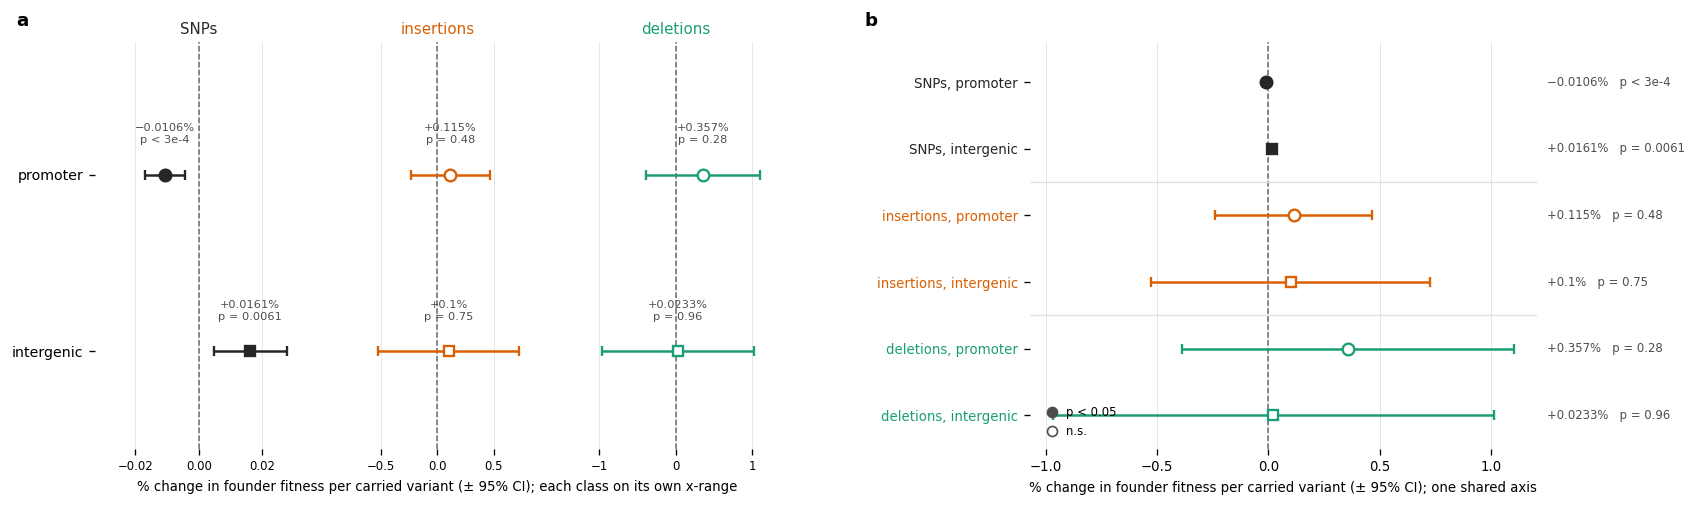

Supplementary Figure S3 — full model on mean fitness (all terms fitted together):
                  term % per variant               95% CI per SD variants per SD Wald p permutation p
        SNPs, promoter      −0.0106% [−0.017%, −0.00427%] −0.999         9,414.3  0.001      p < 3e-4
      SNPs, intergenic      +0.0161% [+0.0046%, +0.0276%] +0.702         4,353.4 0.0061              
  insertions, promoter       +0.115%   [−0.238%, +0.468%] +0.100            86.8   0.52      p = 0.48
insertions, intergenic         +0.1%   [−0.527%, +0.728%] +0.039            38.6   0.75              
   deletions, promoter       +0.357%     [−0.389%, +1.1%] +0.104            29.2   0.35      p = 0.28
 deletions, intergenic      +0.0233%    [−0.968%, +1.01%] +0.003            14.6   0.96              
assembly route (cactus − short-read): +0.146 ± 0.124 (Wald p = 0.24)


In [7]:

fig=plt.figure(figsize=(15.5,4.4)); gsf=fig.add_gridspec(1,2,width_ratios=[1.35,1],wspace=0.42)
def pval(t): return FM.loc[t,"p_perm"] if t.endswith("promoter") else FM.loc[t,"p_wald"]
def plab(t): return pfmt(pval(t),NPERM) if t.endswith("promoter") else pfmt(pval(t))
# (a) one small panel per class, own symmetric x-range
gsa=gsf[0,0].subgridspec(1,3,wspace=0.15)
for ci,k in enumerate(KINDS):
    a=fig.add_subplot(gsa[0,ci]); style(a); a.axvline(0,color="0.4",lw=0.9,ls="--")
    ext=max(abs(100*FM.loc[f"{k}_{x}","beta_per_variant"])+2.3*100*FM.loc[f"{k}_{x}","se_per_variant"] for x in ("promoter","intergenic"))
    for yi,(x,mk) in enumerate((("promoter","o"),("intergenic","s"))):
        t=f"{k}_{x}"; b=100*FM.loc[t,"beta_per_variant"]; s_=100*FM.loc[t,"se_per_variant"]; sig=pval(t)<0.05
        a.errorbar(b,yi,xerr=1.96*s_,fmt=mk,ms=7 if x=="promoter" else 6,color=KC[k],mfc=KC[k] if sig else "white",mew=1.4,capsize=3,elinewidth=1.5)
        a.annotate(f"{pct(b)}\n{plab(t)}",xy=(b,yi-0.17),ha="center",va="bottom",fontsize=6.8,color="0.3")
    a.set_xlim(-ext*1.1,ext*1.1); a.set_ylim(1.55,-0.75); a.set_yticks([0,1])
    a.set_yticklabels(["promoter","intergenic"] if ci==0 else ["",""],fontsize=8.5)
    if ci>0: a.tick_params(axis="y",left=False)
    a.tick_params(axis="x",labelsize=7); a.annotate(YL[k],xy=(0.5,1.02),xycoords="axes fraction",ha="center",fontsize=9,color=KC[k])
    if ci==0: panel(a,"a",x=-0.32)
    if ci==1: a.set_xlabel("% change in founder fitness per carried variant (± 95% CI); each class on its own x-range",fontsize=8)
# (b) all six on one shared axis
a=fig.add_subplot(gsf[0,1]); style(a); panel(a,"b",x=-0.3); a.axvline(0,color="0.4",lw=0.9,ls="--")
rows_=[(f"{k}_{x}",k,x) for k in KINDS for x in ("promoter","intergenic")]
for yi,(t,k,x) in enumerate(rows_):
    b=100*FM.loc[t,"beta_per_variant"]; s_=100*FM.loc[t,"se_per_variant"]; sig=pval(t)<0.05
    a.errorbar(b,yi,xerr=1.96*s_,fmt="o" if x=="promoter" else "s",ms=7 if x=="promoter" else 6,color=KC[k],mfc=KC[k] if sig else "white",mew=1.4,capsize=3,elinewidth=1.5)
    a.annotate(f"{pct(b)}   {plab(t)}",xy=(1.02,yi),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.3",annotation_clip=False)
    if yi in (1,3): a.axhline(yi+0.5,color="0.88",lw=0.8)
a.set_yticks(range(len(rows_))); a.set_yticklabels([f"{YL[k]}, {'promoter' if x=='promoter' else 'intergenic'}" for _,k,x in rows_],fontsize=8)
for tl,(_,k,_) in zip(a.get_yticklabels(),rows_): tl.set_color(KC[k])
a.set_ylim(len(rows_)-0.5,-0.6); a.set_xlabel("% change in founder fitness per carried variant (± 95% CI); one shared axis",fontsize=8)
a.errorbar([],[],fmt="o",color="0.3",ms=6,label="p < 0.05"); a.errorbar([],[],fmt="o",color="0.3",mfc="white",ms=6,label="n.s.")
a.legend(fontsize=7,loc="lower left",handletextpad=0.2)
save(fig,"burden_promoter_model_effects"); plt.show()
T=pd.DataFrame({"term":[f"{YL[t.split('_')[0]]}, {'promoter' if t.endswith('promoter') else 'intergenic'}" for t in FM.index[:6]],
                "% per variant":[pct(100*FM.loc[t,'beta_per_variant']) for t in FM.index[:6]],
                "95% CI":[f"[{pct(100*(FM.loc[t,'beta_per_variant']-1.96*FM.loc[t,'se_per_variant']))}, {pct(100*(FM.loc[t,'beta_per_variant']+1.96*FM.loc[t,'se_per_variant']))}]" for t in FM.index[:6]],
                "per SD":[f"{FM.loc[t,'beta_sd']:+.3f}".replace("-",M) for t in FM.index[:6]],
                "variants per SD":[f"{FM.loc[t,'variants_per_sd']:,.1f}" for t in FM.index[:6]],
                "Wald p":[f"{FM.loc[t,'p_wald']:.2g}" for t in FM.index[:6]],
                "permutation p":[pfmt(FM.loc[t,'p_perm'],NPERM) if t.endswith('promoter') else "" for t in FM.index[:6]]})
print("Supplementary Figure S3 — full model on mean fitness (all terms fitted together):"); print(T.to_string(index=False))
print(f"assembly route (cactus − short-read): {FM.loc['cactus','beta_sd']:+.3f} ± {FM.loc['cactus','se_sd']:.3f} (Wald p = {FM.loc['cactus','p_wald']:.2g})")


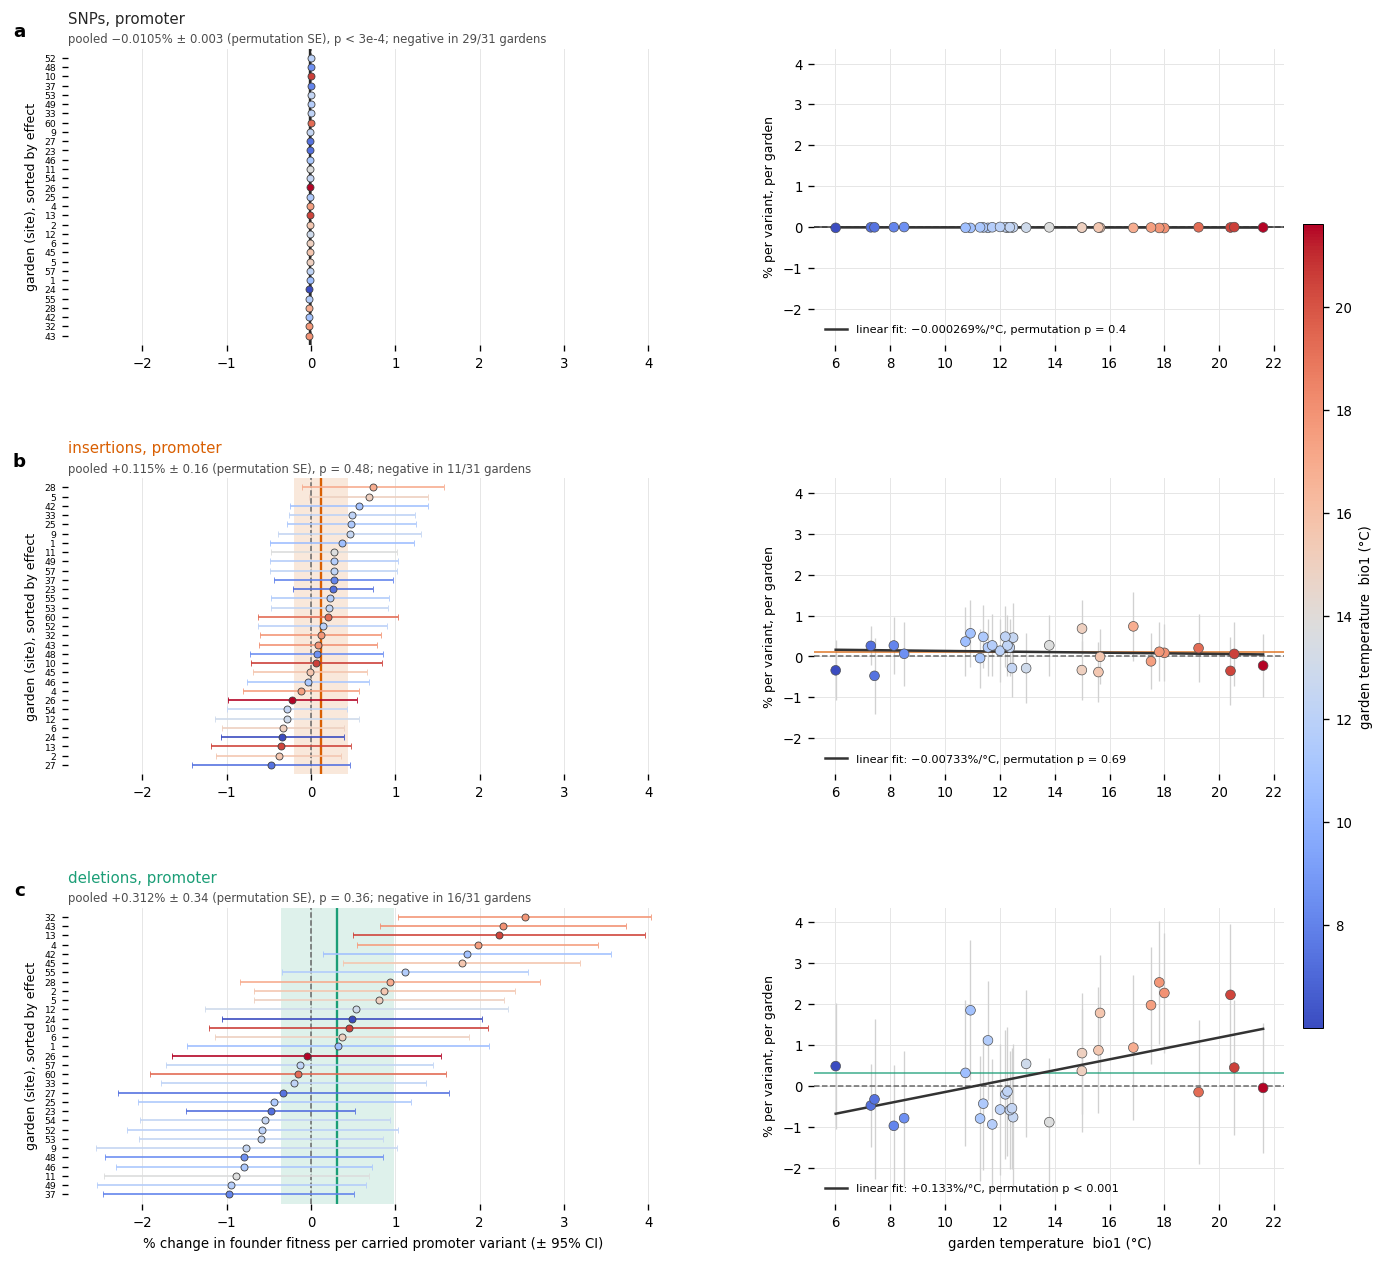

Supplementary Figure S4 — per-garden summary, promoter terms:
promoter term                          SNPs      insertions        deletions
pooled % per variant               −0.0105%         +0.115%          +0.312%
SE (permutation)                      0.003            0.16             0.34
SE (textbook)                        0.0012           0.068             0.14
pooled p (perm.)                   p < 3e-4        p = 0.48         p = 0.36
gardens < 0                           29/31           11/31            16/31
slope %/°C (equal weights)       −0.000269%       −0.00733%          +0.133%
slope p (perm.)                     p = 0.4        p = 0.69        p < 0.001
worst leave-one-out p (OLS)  0.64 (site 43)  0.96 (site 13)  0.012 (site 13)


In [8]:

B1=FG.drop_duplicates("site").bio1; NORM=mpl.colors.Normalize(B1.min(),B1.max()); CMAP=plt.get_cmap("coolwarm")
def mreg(b,v,x):
    w=1/v; X=np.column_stack([np.ones(b.size),x]); XtW=X.T*w; bh=np.linalg.solve(XtW@X,XtW@b); return bh,np.sqrt(np.diag(np.linalg.inv(XtW@X)))
fig=plt.figure(figsize=(13.5,12.5)); gsg=fig.add_gridspec(3,2,width_ratios=[1.3,1],wspace=0.25,hspace=0.45); OUTG=[]; AXL=[]; AXR=[]
for r_,k in enumerate(KINDS):
    t=f"{k}_promoter"; g=FG[FG.term==t].sort_values("beta_sd").reset_index(drop=True); r=FM.loc[t]; sc=r.beta_per_variant/r.beta_sd
    b=100*g.beta_per_variant.to_numpy(); se=100*g.se_per_variant.to_numpy(); x=g.bio1.to_numpy(); v=se**2
    po=100*r.pooled_sd*sc; pse=100*r.pooled_se_perm*sc; pse_ind=100*r.pooled_se_independent*sc
    a=fig.add_subplot(gsg[r_,0]); AXL.append(a); style(a); panel(a,"abc"[r_],x=-0.07); a.axvline(0,color="0.4",lw=0.9,ls="--")
    a.axvspan(po-1.96*pse,po+1.96*pse,color=KC[k],alpha=0.14,lw=0); a.axvline(po,color=KC[k],lw=1.4)
    for yi in range(len(g)):
        c_=CMAP(NORM(g.bio1[yi])); a.errorbar(b[yi],yi,xerr=1.96*se[yi],fmt="o",ms=4.2,color=c_,mec="0.25",mew=0.5,ecolor=c_,elinewidth=1.0,capsize=1.6)
    a.set_yticks(range(len(g))); a.set_yticklabels(g.site.astype(int),fontsize=5.5); a.set_ylim(-1,len(g)); a.set_ylabel("garden (site), sorted by effect",fontsize=7.5)
    a.annotate(f"{YL[k]}, promoter", xy=(0.0,1.075),xycoords="axes fraction",fontsize=9,color=KC[k],va="bottom",annotation_clip=False)
    a.annotate(f"pooled {pct(po)} ± {pse:.2g} (permutation SE), {pfmt(r.p_perm_pooled,NPERM)}; negative in {int(r.negative_in)}/{NG} gardens",
               xy=(0.0,1.01),xycoords="axes fraction",ha="left",va="bottom",fontsize=7,color="0.3",annotation_clip=False)
    if r_==2: a.set_xlabel("% change in founder fitness per carried promoter variant (± 95% CI)",fontsize=8)
    a=fig.add_subplot(gsg[r_,1]); AXR.append(a); style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--"); a.axhline(po,color=KC[k],lw=1.1,alpha=0.7)
    a.errorbar(x,b,yerr=1.96*se,fmt="none",ecolor="0.82",elinewidth=0.8,zorder=1)
    a.scatter(x,b,s=34,c=x,cmap=CMAP,norm=NORM,linewidth=0.4,edgecolor="0.3",zorder=3)
    su,_=mreg(b,np.ones_like(v),x); ews,ewp=ew_slope(t); xx=np.linspace(x.min(),x.max(),50)
    a.plot(xx,su[0]+su[1]*xx,color="0.2",lw=1.5,label=f"linear fit: {pct(su[1])}/°C, permutation {pfmt(ewp,NPERM)}")
    a.set_ylabel("% per variant, per garden",fontsize=7.5); a.legend(fontsize=6.8,loc="lower left")
    if r_==2: a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
    LOO=[]
    for i in range(len(b)):
        m_=np.ones(len(b),bool); m_[i]=False; lr=stats.linregress(x[m_],b[m_]); LOO.append((int(g.site[i]),lr.slope,lr.pvalue))
    L_=pd.DataFrame(LOO,columns=["site","slope","p"]).sort_values("p",ascending=False).iloc[0]
    OUTG.append({"promoter term":YL[k],"pooled % per variant":pct(po),"SE (permutation)":f"{pse:.2g}","SE (textbook)":f"{pse_ind:.2g}",
                 "pooled p (perm.)":pfmt(r.p_perm_pooled,NPERM),"gardens < 0":f"{int(r.negative_in)}/{NG}",
                 "slope %/°C (equal weights)":pct(su[1]),"slope p (perm.)":pfmt(ewp,NPERM),"worst leave-one-out p (OLS)":f"{L_.p:.2g} (site {int(L_.site)})"})
xl=[a.get_xlim() for a in AXL]; yl=[a.get_ylim() for a in AXR]                        # one shared per-variant scale
for a in AXL: a.set_xlim(min(v_[0] for v_ in xl),max(v_[1] for v_ in xl))
for a in AXR: a.set_ylim(min(v_[0] for v_ in yl),max(v_[1] for v_ in yl))
for a in AXL[:2]+AXR[:2]: a.tick_params(labelbottom=True)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM,cmap=CMAP),ax=AXL+AXR,pad=0.015,fraction=0.016,aspect=40); cb.set_label("garden temperature  bio1 (°C)",fontsize=8)
save(fig,"burden_promoter_model_by_garden"); plt.show()
print("Supplementary Figure S4 — per-garden summary, promoter terms:"); print(pd.DataFrame(OUTG).T.to_string(header=False))


### Supplementary Figure S5 — the intergenic terms of the same promoter model, garden by garden

The intergenic insertion and deletion coefficients from the promoter model (the within-class baseline of
Supplementary Figures S3–S4), in the Figure 2 layout, on the same per-variant scale. Only the promoter
terms were permuted, so here the pooled estimate carries the textbook inverse-variance SE (too small by
the same ≈ 2–2.5× as in Figure 2) and the slope an ordinary least-squares p — both anti-conservative, so
a flat result is not at risk from them. Compare with Supplementary Figure S4c (promoter deletions).

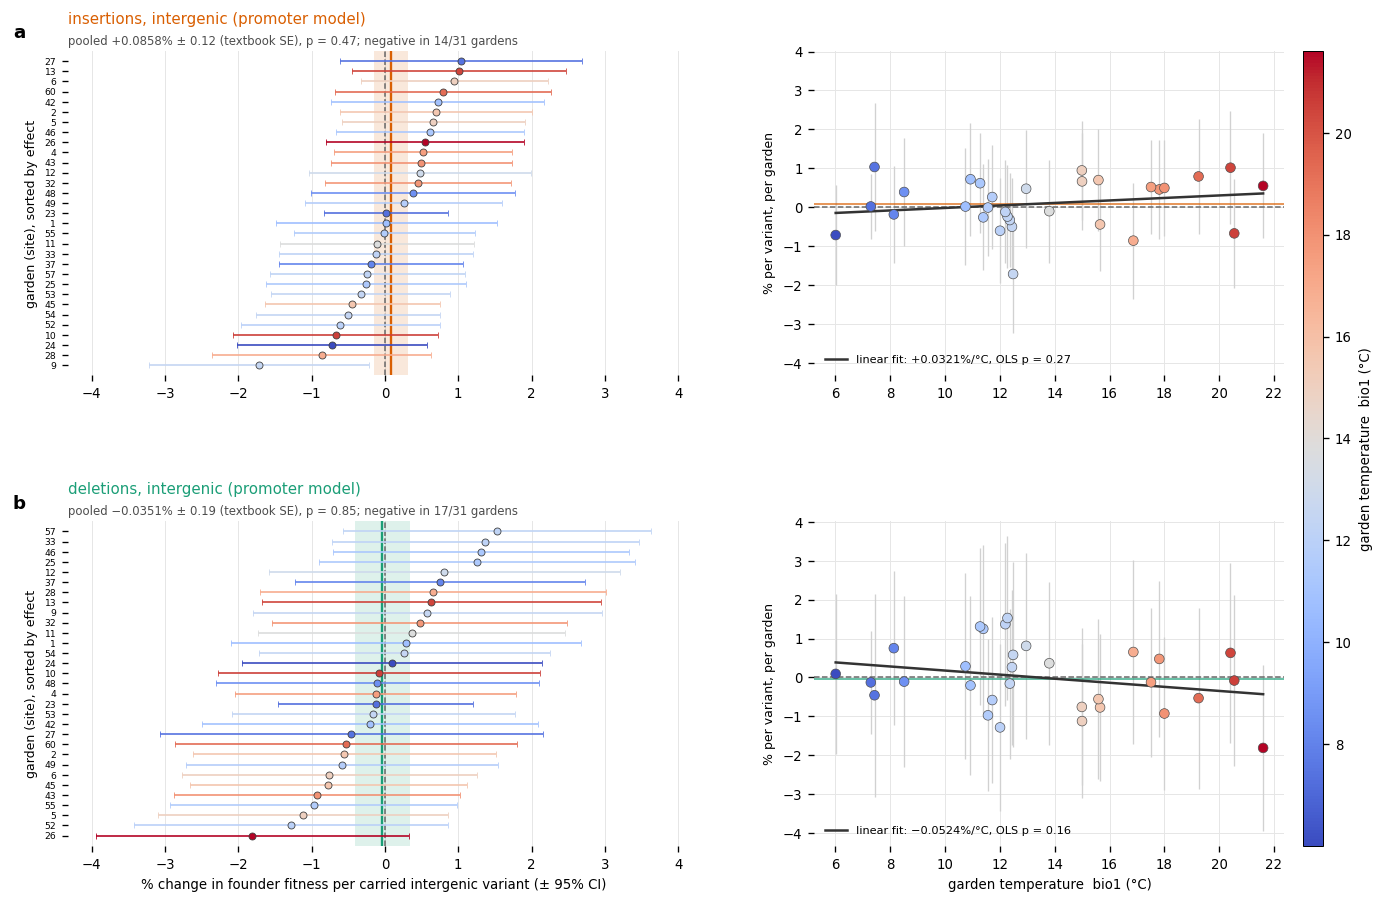

Supplementary Figure S5 — intergenic terms of the promoter model, per garden:
intergenic term       insertions  deletions
pooled % per variant    +0.0858%   −0.0351%
SE (textbook)               0.12       0.19
p                           0.47       0.85
gardens < 0                14/31      17/31
slope %/°C              +0.0321%   −0.0524%
slope p (OLS)               0.27       0.16


In [9]:

fig=plt.figure(figsize=(13.5,8.6)); gsg=fig.add_gridspec(2,2,width_ratios=[1.3,1],wspace=0.25,hspace=0.45); AXL=[]; AXR=[]; OUT=[]
for r_,k in enumerate(("ins","del")):
    t=f"{k}_intergenic"; g=FG[FG.term==t].sort_values("beta_sd").reset_index(drop=True)
    b=100*g.beta_per_variant.to_numpy(); se=100*g.se_per_variant.to_numpy(); x=g.bio1.to_numpy(); w=1/se**2
    po=(w*b).sum()/w.sum(); pse=np.sqrt(1/w.sum()); pp_=2*stats.norm.sf(abs(po/pse))
    a=fig.add_subplot(gsg[r_,0]); AXL.append(a); style(a); panel(a,"ab"[r_],x=-0.07); a.axvline(0,color="0.4",lw=0.9,ls="--")
    a.axvspan(po-1.96*pse,po+1.96*pse,color=KC[k],alpha=0.14,lw=0); a.axvline(po,color=KC[k],lw=1.4)
    for yi in range(len(g)):
        c_=CMAP(NORM(g.bio1[yi])); a.errorbar(b[yi],yi,xerr=1.96*se[yi],fmt="o",ms=4.2,color=c_,mec="0.25",mew=0.5,ecolor=c_,elinewidth=1.0,capsize=1.6)
    a.set_yticks(range(len(g))); a.set_yticklabels(g.site.astype(int),fontsize=5.5); a.set_ylim(-1,len(g)); a.set_ylabel("garden (site), sorted by effect",fontsize=7.5)
    a.annotate(f"{YL[k]}, intergenic (promoter model)",xy=(0,1.075),xycoords="axes fraction",fontsize=9,color=KC[k],va="bottom",annotation_clip=False)
    a.annotate(f"pooled {pct(po)} ± {pse:.2g} (textbook SE), p = {pp_:.2g}; negative in {(b<0).sum()}/{NG} gardens",
               xy=(0,1.01),xycoords="axes fraction",fontsize=7,color="0.3",va="bottom",annotation_clip=False)
    if r_==1: a.set_xlabel("% change in founder fitness per carried intergenic variant (± 95% CI)",fontsize=8)
    a=fig.add_subplot(gsg[r_,1]); AXR.append(a); style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--"); a.axhline(po,color=KC[k],lw=1.1,alpha=0.7)
    a.errorbar(x,b,yerr=1.96*se,fmt="none",ecolor="0.82",elinewidth=0.8,zorder=1); a.scatter(x,b,s=34,c=x,cmap=CMAP,norm=NORM,linewidth=0.4,edgecolor="0.3",zorder=3)
    lr=stats.linregress(x,b); xx=np.linspace(x.min(),x.max(),50)
    a.plot(xx,lr.intercept+lr.slope*xx,color="0.2",lw=1.5,label=f"linear fit: {pct(lr.slope)}/°C, OLS p = {lr.pvalue:.2g}")
    a.set_ylabel("% per variant, per garden",fontsize=7.5); a.legend(fontsize=6.8,loc="lower left")
    if r_==1: a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
    OUT.append({"intergenic term":YL[k],"pooled % per variant":pct(po),"SE (textbook)":f"{pse:.2g}","p":f"{pp_:.2g}",
                "gardens < 0":f"{(b<0).sum()}/{NG}","slope %/°C":pct(lr.slope),"slope p (OLS)":f"{lr.pvalue:.2g}"})
xl=[a.get_xlim() for a in AXL]; yl=[a.get_ylim() for a in AXR]
for a in AXL: a.set_xlim(min(v_[0] for v_ in xl),max(v_[1] for v_ in xl))
for a in AXR: a.set_ylim(min(v_[0] for v_ in yl),max(v_[1] for v_ in yl))
for a in AXL[:1]+AXR[:1]: a.tick_params(labelbottom=True)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM,cmap=CMAP),ax=AXL+AXR,pad=0.015,fraction=0.016,aspect=40); cb.set_label("garden temperature  bio1 (°C)",fontsize=8)
save(fig,"burden_promoter_model_by_garden_intergenic"); plt.show()
print("Supplementary Figure S5 — intergenic terms of the promoter model, per garden:"); print(pd.DataFrame(OUT).T.to_string(header=False))


## One-stage model — all founder × garden observations in one mixed model

Everything above is fitted on 231 founder values (the mean over gardens) or garden by garden. Here the
same question is asked of all **231 founders × 31 gardens = 7,161 observations** at once, so the overall
effect, the garden-to-garden variation and the dependence on garden temperature come out of one model.

**Data.** One row per founder *f* and garden *s*: *y*<sub>fs</sub> = log[(*H*<sub>0,f</sub> + Δ*H*<sub>s,f</sub> + 10⁻⁵)/(*H*<sub>0,f</sub> + 10⁻⁵)]
(the same fitness as above, not averaged); the founder's nine standardised burden rates (SNPs, insertions,
deletions × coding, promoter, intergenic) and assembly route; garden bio1, centred on the mean of the 31
gardens (so interaction terms are per °C and main effects are at the average garden). No missing cells.

**Models** (R formulas exactly as fitted; `kin` carries the kinship matrix, see below):

- **A — overall effects:** `y ~ <9 burden rates> + cactus + (1 | garden) + (1 | kin) + (1 | fid)`
- **B — the climate test:** A + `<tested> : bio1c` for the six coding and promoter terms + `(0 + <tested> | garden)`,
  one independent random garden slope per tested term
- **C — B without the random garden slopes** (to show what they do)

`garden` = random garden intercept; `kin` = founder genetic effect with covariance σ²<sub>kin</sub>**K**
(**K** = the 231 × 231 SNP kinship used throughout); `fid` = an independent founder effect, because each
founder is measured in 31 gardens. The random garden slope lets each garden have its own burden effect
around the overall one; without it, the 31 gardens would count as independent evidence for every burden
effect even though they share one founder set.

**How kinship enters.** lme4 cannot take a known covariance matrix, so the `(1 | kin)` design is replaced
by *Z*·*L*, with **K** = *LL*ᵀ from the eigendecomposition of **K** — lme4's documented modular interface
(`lFormula` → `mkLmerDevfun` → `optimizeLmer`; `_sv_burden_onestage.R`). This is what the lme4qtl package
does internally; the same models refitted with `lme4qtl::relmatLmer` (`_sv_burden_onestage_lme4qtl_check.R`)
give identical estimates (checked below). REML fits; Wald z-tests; for each climate interaction also a
likelihood-ratio test (ML refits of B with and without that one interaction).

*Caveats.* Frequencies within a garden compete (a founder can only rise if others fall), which none of these
models represent, so these p-values are model-based; the founder-label permutations of the two-stage
analysis remain the reference test. The independent founder effect `fid` is estimated at zero (kinship
absorbs all founder-level variation), which triggers lme4's "singular fit" note; it is harmless.

In [10]:

OS=f"{G}/onestage"
oA=pd.read_csv(f"{OS}/coef_A.csv").set_index("term"); oB=pd.read_csv(f"{OS}/coef_B.csv").set_index("term"); oC=pd.read_csv(f"{OS}/coef_C.csv").set_index("term")
qA=pd.read_csv(f"{OS}/lme4qtl_coef_A.csv").set_index("term"); qB=pd.read_csv(f"{OS}/lme4qtl_coef_B.csv").set_index("term")
VC=pd.read_csv(f"{OS}/varcomp.csv"); LRT=pd.read_csv(f"{OS}/lrt_B.csv").set_index("term") if os.path.exists(f"{OS}/lrt_B.csv") else None
GB_=pd.read_csv(f"{OS}/garden_B.csv"); VB=pd.read_csv(f"{OS}/vcov_B.csv",index_col=0)
TS=pd.read_csv(f"{G}/sv_burden_full_model_event_CDS+promoter.csv").set_index("term")          # the two-stage fit of the same terms
LONG=pd.read_csv(f"{OS}/long.csv",usecols=["founder","garden","bio1"])
TERMS9=[f"{k}_{x}" for k in KINDS for x in ("CDS","promoter","intergenic")]; TESTED6=[f"{k}_{x}" for k in KINDS for x in ("CDS","promoter")]
print(f"data: {len(LONG):,} rows = {LONG.founder.nunique()} founders x {LONG.garden.nunique()} gardens; garden bio1 centred on {LONG.drop_duplicates('garden').bio1.mean():.2f} °C")
fx=" + ".join(TERMS9+["cactus"]); inter=" + ".join(f"{t}:bio1c" for t in TESTED6); sl=" + ".join(f"(0 + {t} | garden)" for t in TESTED6)
print(f"\nmodel A:  y ~ {fx} + (1 | garden) + (1 | kin) + (1 | fid)")
print(f"model B:  y ~ {fx} + {inter} + (1 | garden) + (1 | kin) + (1 | fid) + {sl}")
print("model C:  model B without the (0 + term | garden) slopes")
print(f"\nlme4qtl check: max |difference| in estimates  A {(oA.estimate-qA.estimate).abs().max():.1e},  B {(oB.estimate-qB.estimate).abs().max():.1e};"
      f"  in SEs  A {(oA.se-qA.se).abs().max():.1e},  B {(oB.se-qB.se).abs().max():.1e}")
print("\nvariance components, model B:"); print(VC.assign(vcov=VC.vcov.round(4)).rename(columns={"grp":"group","var1":"term","vcov":"variance"}).to_string(index=False))


data: 7,161 rows = 231 founders x 31 gardens; garden bio1 centred on 13.51 °C

model A:  y ~ snp_CDS + snp_promoter + snp_intergenic + ins_CDS + ins_promoter + ins_intergenic + del_CDS + del_promoter + del_intergenic + cactus + (1 | garden) + (1 | kin) + (1 | fid)
model B:  y ~ snp_CDS + snp_promoter + snp_intergenic + ins_CDS + ins_promoter + ins_intergenic + del_CDS + del_promoter + del_intergenic + cactus + snp_CDS:bio1c + snp_promoter:bio1c + ins_CDS:bio1c + ins_promoter:bio1c + del_CDS:bio1c + del_promoter:bio1c + (1 | garden) + (1 | kin) + (1 | fid) + (0 + snp_CDS | garden) + (0 + snp_promoter | garden) + (0 + ins_CDS | garden) + (0 + ins_promoter | garden) + (0 + del_CDS | garden) + (0 + del_promoter | garden)
model C:  model B without the (0 + term | garden) slopes

lme4qtl check: max |difference| in estimates  A 1.2e-10,  B 7.3e-06;  in SEs  A 1.6e-10,  B 2.8e-05

variance components, model B:
   group         term  variance
     fid  (Intercept)    0.0000
     kin  (Intercept

### Figure O1 — overall effects: one model on 7,161 observations vs the founder-mean model

Model A against the two-stage full model with the same nine burden terms (`CONTEXT=CDS,promoter`), per SD
of each rate. Because every founder is measured in every garden, a random garden intercept cannot change a
founder-level effect, so the two should agree.

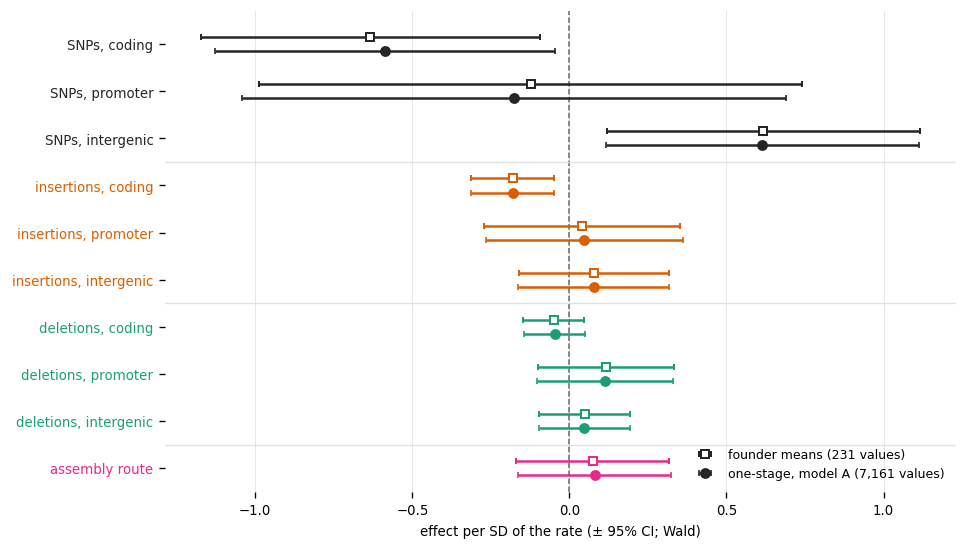

                  term                 one-stage             founder means
          SNPs, coding  -0.588 ± 0.276 (p 0.033)  -0.634 ± 0.275 (p 0.021)
        SNPs, promoter   -0.175 ± 0.442 (p 0.69)   -0.123 ± 0.441 (p 0.78)
      SNPs, intergenic  +0.614 ± 0.254 (p 0.016)  +0.617 ± 0.254 (p 0.015)
    insertions, coding -0.181 ± 0.067 (p 0.0071) -0.180 ± 0.067 (p 0.0074)
  insertions, promoter   +0.048 ± 0.160 (p 0.76)   +0.039 ± 0.159 (p 0.81)
insertions, intergenic   +0.077 ± 0.122 (p 0.53)   +0.078 ± 0.122 (p 0.52)
     deletions, coding   -0.047 ± 0.049 (p 0.35)   -0.050 ± 0.049 (p 0.31)
   deletions, promoter   +0.114 ± 0.111 (p 0.31)   +0.117 ± 0.111 (p 0.29)
 deletions, intergenic   +0.048 ± 0.074 (p 0.51)   +0.049 ± 0.074 (p 0.51)
        assembly route   +0.081 ± 0.125 (p 0.52)   +0.074 ± 0.124 (p 0.55)


In [11]:

LAB=lambda t: f"{YL[t.split('_')[0]]}, {'coding' if t.endswith('CDS') else t.split('_')[1]}" if t!="cactus" else "assembly route"
rows_=TERMS9+["cactus"]
fig,a=plt.subplots(figsize=(8.5,5.2)); style(a); a.axvline(0,color="0.4",lw=0.9,ls="--")
for yi,t in enumerate(rows_):
    col=KC[t.split("_")[0]] if t!="cactus" else "#E7298A"
    a.errorbar(TS.loc[t,"beta_sd"],yi-0.15,xerr=1.96*TS.loc[t,"se_sd"],fmt="s",ms=5,color=col,mfc="white",mew=1.2,capsize=2,label="founder means (231 values)" if yi==0 else None)
    a.errorbar(oA.loc[t,"estimate"],yi+0.15,xerr=1.96*oA.loc[t,"se"],fmt="o",ms=5.5,color=col,capsize=2,label="one-stage, model A (7,161 values)" if yi==0 else None)
    if yi in (2,5,8): a.axhline(yi+0.5,color="0.88",lw=0.8)
a.set_yticks(range(len(rows_))); a.set_yticklabels([LAB(t) for t in rows_],fontsize=8); a.set_ylim(len(rows_)-0.5,-0.7)
for tl,t in zip(a.get_yticklabels(),rows_): tl.set_color(KC[t.split("_")[0]] if t!="cactus" else "#E7298A")
a.set_xlabel("effect per SD of the rate (± 95% CI; Wald)",fontsize=8); a.legend(fontsize=7.5,loc="lower right")
save(fig,"onestage_main_effects"); plt.show()
print(pd.DataFrame({"term":[LAB(t) for t in rows_],"one-stage":[f"{oA.loc[t,'estimate']:+.3f} ± {oA.loc[t,'se']:.3f} (p {oA.loc[t,'p']:.2g})" for t in rows_],
                    "founder means":[f"{TS.loc[t,'beta_sd']:+.3f} ± {TS.loc[t,'se_sd']:.3f} (p {TS.loc[t,'p_wald']:.2g})" for t in rows_]}).to_string(index=False))


### Figure O2 — the climate test: burden × garden temperature

The six interaction coefficients of model B (per SD of burden per °C of garden bio1): the change in a
term's effect per degree of garden temperature. Filled = with the random garden slopes (model B, the
honest version); open = without them (model C), which shows how much the garden-to-garden variation
matters. The likelihood-ratio p (ML, model B with vs without that one interaction) is printed at the
right when available.

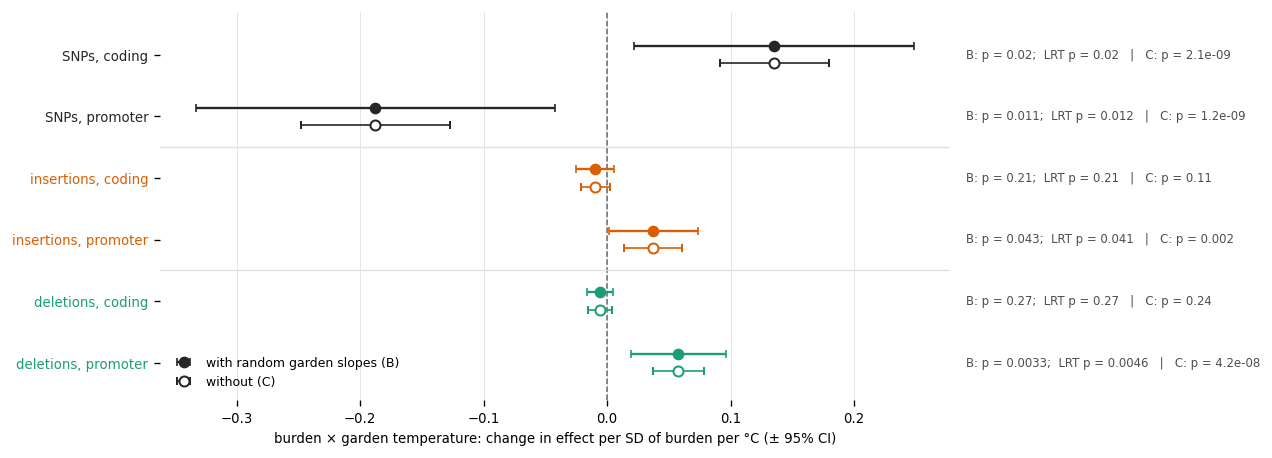

In [12]:

fig,a=plt.subplots(figsize=(8.5,4.2)); style(a); a.axvline(0,color="0.4",lw=0.9,ls="--")
for yi,t in enumerate(TESTED6):
    col=KC[t.split("_")[0]]; i=f"{t}:bio1c"
    a.errorbar(oB.loc[i,"estimate"],yi-0.14,xerr=1.96*oB.loc[i,"se"],fmt="o",ms=6,color=col,capsize=2.5,elinewidth=1.4,label="with random garden slopes (B)" if yi==0 else None)
    a.errorbar(oC.loc[i,"estimate"],yi+0.14,xerr=1.96*oC.loc[i,"se"],fmt="o",ms=6,color=col,mfc="white",mew=1.2,capsize=2.5,elinewidth=1.0,label="without (C)" if yi==0 else None)
    txt=f"B: p = {oB.loc[i,'p']:.2g}"+(f";  LRT p = {LRT.loc[i,'p']:.2g}" if LRT is not None and i in LRT.index else "")+f"   |   C: p = {oC.loc[i,'p']:.2g}"
    a.annotate(txt,xy=(1.02,yi),xycoords=("axes fraction","data"),va="center",fontsize=7,color="0.3",annotation_clip=False)
    if yi in (1,3): a.axhline(yi+0.5,color="0.88",lw=0.8)
a.set_yticks(range(6)); a.set_yticklabels([LAB(t) for t in TESTED6],fontsize=8); a.set_ylim(5.6,-0.7)
for tl,t in zip(a.get_yticklabels(),TESTED6): tl.set_color(KC[t.split("_")[0]])
a.set_xlabel("burden × garden temperature: change in effect per SD of burden per °C (± 95% CI)",fontsize=8); a.legend(fontsize=7.5,loc="lower left")
save(fig,"onestage_climate_interactions"); plt.show()
if LRT is None: print("likelihood-ratio tests not yet available (lrt_B.csv) — rebuild when `_sv_burden_onestage.R` has finished")


### Figure O3 — each garden's effect, from the one model

For the four SV terms, each garden's total effect from model B — the overall effect plus the temperature
term plus that garden's own random slope (β + γ·bio1 + *b*<sub>s</sub>) — against garden temperature,
with the model's fitted line (β + γ·bio1) and its 95% confidence band. Bars = ± 1.96 conditional SD of the
garden's random slope. Unlike Figure 2, the gardens are not fitted separately: noisy gardens are pulled
towards the line (shrinkage). Converted to % change in fitness per carried variant with the same
per-variant scale as Figure 1 (one SD of the rate = the number of variants given in Figure 1).

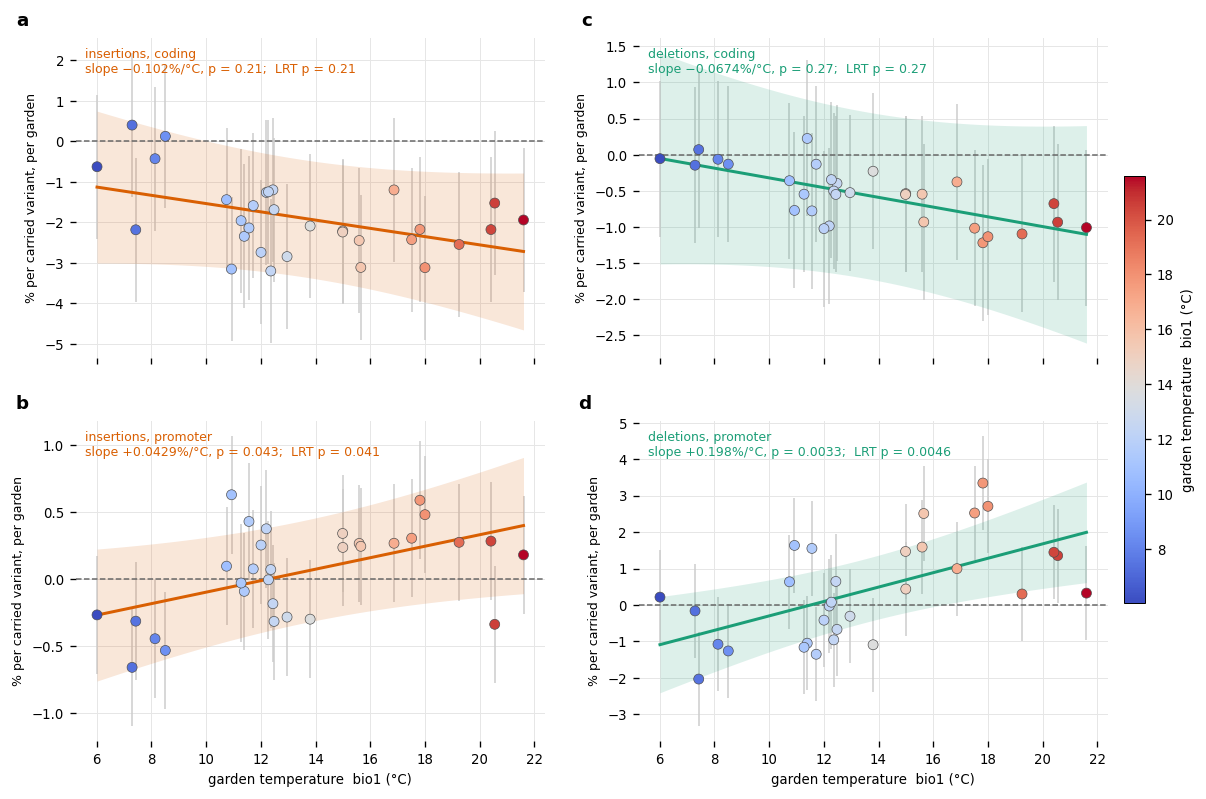

model B, tested terms:
                term overall (per SD) × bio1 (per SD per °C) Wald p  LRT p random-slope SD
        SNPs, coding   -0.604 ± 0.351       +0.1353 ± 0.0579   0.02   0.02           1.204
      SNPs, promoter   -0.157 ± 0.519       -0.1877 ± 0.0741  0.011  0.012           1.524
  insertions, coding   -0.181 ± 0.070       -0.0097 ± 0.0077   0.21   0.21           0.117
insertions, promoter   +0.045 ± 0.170       +0.0372 ± 0.0184  0.043  0.041           0.321
   deletions, coding   -0.048 ± 0.050       -0.0058 ± 0.0052   0.27   0.27           0.053
 deletions, promoter   +0.115 ± 0.130       +0.0577 ± 0.0196 0.0033 0.0046           0.378


In [13]:

SV4=[t for t in TESTED6 if not t.startswith("snp")]
fig,axs=plt.subplots(2,2,figsize=(11.5,7.6),sharex=True); B1s=LONG.drop_duplicates("garden").bio1; NORM_=mpl.colors.Normalize(B1s.min(),B1s.max()); CM=plt.get_cmap("coolwarm")
bc0=B1s.mean(); xx=np.linspace(B1s.min(),B1s.max(),60); xc=xx-bc0
for a,t,letter in zip(axs.T.ravel(),["ins_CDS","ins_promoter","del_CDS","del_promoter"],"abcd"):
    style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--"); panel(a,letter,x=-0.1)
    sc=100/TS.loc[t,"variants_per_sd"]                                          # per SD -> % per carried variant
    g=GB_[GB_.term==t]; a.errorbar(g.bio1,sc*g.total,yerr=1.96*sc*g.cond_sd,fmt="none",ecolor="0.8",elinewidth=0.9,zorder=1)
    a.scatter(g.bio1,sc*g.total,c=g.bio1,cmap=CM,norm=NORM_,s=36,linewidth=0.4,edgecolor="0.3",zorder=3)
    b0,b1=oB.loc[t,"estimate"],oB.loc[f"{t}:bio1c","estimate"]; i0,i1=t,f"{t}:bio1c"
    v=VB.loc[i0,i0]+xc**2*VB.loc[i1,i1]+2*xc*VB.loc[i0,i1]; fit=b0+b1*xc
    a.fill_between(xx,sc*(fit-1.96*np.sqrt(v)),sc*(fit+1.96*np.sqrt(v)),color=KC[t.split("_")[0]],alpha=0.15,lw=0)
    a.plot(xx,sc*fit,color=KC[t.split("_")[0]],lw=1.8)
    lr=f";  LRT p = {LRT.loc[i1,'p']:.2g}" if LRT is not None and i1 in LRT.index else ""
    a.annotate(f"{LAB(t)}\nslope {pct(sc*b1)}/°C, p = {oB.loc[i1,'p']:.2g}{lr}",xy=(0.02,0.97),xycoords="axes fraction",va="top",fontsize=7.5,color=KC[t.split("_")[0]])
    a.set_ylabel("% per carried variant, per garden",fontsize=7.5)
    if letter in "bd": a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM_,cmap=CM),ax=axs,pad=0.015,fraction=0.02); cb.set_label("garden temperature  bio1 (°C)",fontsize=8)
save(fig,"onestage_garden_effects"); plt.show()
T_=pd.DataFrame([{"term":LAB(t),"overall (per SD)":f"{oB.loc[t,'estimate']:+.3f} ± {oB.loc[t,'se']:.3f}","× bio1 (per SD per °C)":f"{oB.loc[t+':bio1c','estimate']:+.4f} ± {oB.loc[t+':bio1c','se']:.4f}",
                  "Wald p":f"{oB.loc[t+':bio1c','p']:.2g}","LRT p":(f"{LRT.loc[t+':bio1c','p']:.2g}" if LRT is not None and t+':bio1c' in LRT.index else "pending"),
                  "random-slope SD":f"{np.sqrt(VC[(VC.var1==t)].vcov.iloc[0]):.3f}"} for t in TESTED6])
print("model B, tested terms:"); print(T_.to_string(index=False))


## Methods, as run

- **Fitness.** Founder frequencies *H* per pool from kMate (`founder_site_dh.npz`): *H*<sub>0</sub> = mean of
  the 8 seed-mix estimates; *H*<sub>0</sub> + Δ*H*<sub>s</sub> = last-generation frequency in garden *s*
  (plots equally weighted); *y* as in Figure 1, ε = 10⁻⁵.
- **Burden rates** (`_sv_burden_build.py` → `founder_burden_event.csv`): per founder and class, variants
  carried ÷ variants called; shared variants, ≥ 2 carriers, called in ≥ 90% of founders; all SNP records;
  SVs as Truvari events.
- **Model** (`_sv_burden_full_model.py`): linear mixed model, REML by eigendecomposition of the kinship matrix
  (standardised GRM from a 2% draw of SNPs with ≥ 5 carriers; `LMM` class of `_sv_burden_lmm.py`); rates
  standardised for the fit; Wald z-tests. Per-variant coefficient = coefficient per SD ÷ (SD of the rate ×
  median number of that class's variants called per founder).
- **Permutation** (3,000 draws per coding term): the term's rate regressed (OLS) on all other terms, the
  residual shuffled across founders, the same shuffled vector used in the mean-fitness fit and in all 31
  per-garden fits; two-sided p = share of draws at least as extreme. Pooled per-garden coefficient =
  inverse-variance mean, with SE and p from the permutation spread; slope on garden temperature = OLS of
  the 31 per-garden coefficients on garden bio1 (equal weights), p from the same permutation.
- **Supplement** (`_sv_burden_model_simplify.py`, joint models): AIC from maximum-likelihood refits (REML
  likelihoods are not comparable across fixed effects).